# Homework 6: Tree-Based Methods
**Name:** Vishnu Gamini  
**GitHub Username:** vishnugamini  
**USC ID:** 6350365744  
**Course:** DSCI 552

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_curve
from imblearn.over_sampling import SMOTE
from threadpoolctl import threadpool_limits
from IPython.display import display

root = Path("..") if Path("../data/aps_failure").is_dir() else Path(".")
sys.path.insert(0, str(root / "src"))
from analysis_helpers import (
    load_data,
    metrics,
    report_model,
    show_exploration,
    xgb_model,
    validate_boosting,
)

thread_limits = threadpool_limits(limits=4)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
pd.set_option("display.float_format", lambda v: f"{v:.5f}")
results = root / "data/results"
results.mkdir(parents=True, exist_ok=True)

## 1(a). APS Failure data
The official training and test sets remain separate. `pos` = 1 identifies
an APS-related failure; `neg` = 0 identifies another failure cause.
All 170 numeric predictors are retained in every model. Classification uses
probability above 0.5 (ties predict negative); the test set is excluded from hyperparameter selection.

In [2]:
X_train, X_test, y_train, y_test = load_data(root)
counts = pd.DataFrame(
    {"train": np.bincount(y_train), "test": np.bincount(y_test)},
    index=["neg", "pos"],
)
display(counts)
counts.to_csv(results / "class_counts.csv")

,train,test
neg,59000,15625
pos,1000,375


## 1(b)(i). Missing values
Common approaches include deleting incomplete records, single-value imputation
(mean/median/mode), nearest-neighbor imputation, and iterative conditional models
or multiple imputation. Deletion wastes substantial information here; medians
are inexpensive and less sensitive to extreme sensor values than means.

The main analysis fits medians on training data and reuses them on test data;
validation medians are learned inside each training fold. This allows prediction
of an individual future record. The handout's footnote instead suggests using
test-set statistics. A separate sensitivity table below evaluates that approach
without test labels; it uses the whole test batch and is not the main estimate.

In [3]:
imputer = SimpleImputer(strategy="median")
Xi_train = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns
)
Xi_test = imputer.transform(X_test)
missing = pd.DataFrame(
    {
        "train_missing": X_train.isna().sum(),
        "test_missing": X_test.isna().sum(),
        "train_median": imputer.statistics_,
        "test_median": X_test.median(),
    }
)
assert Xi_train.shape[1] == 170
assert np.isfinite(Xi_train).all().all()
assert np.isfinite(Xi_test).all()
missing.to_csv(results / "missing_values.csv")
display(missing[["train_missing", "test_missing"]].sum())

train_missing    850015
test_missing     228680
dtype: int64

## 1(b)(ii). Coefficients of variation
For every imputed training feature, $CV=s/\bar{x}$, using sample standard
deviation (`ddof=1`). [All 170 values](../data/results/coefficient_of_variation.csv)
are saved; the highest 13 appear below. No imputed feature has zero mean.

In [4]:
variation = pd.DataFrame(
    {"mean": Xi_train.mean(), "sample_std": Xi_train.std(ddof=1)}
)
assert variation["mean"].ne(0).all()
variation["CV"] = variation.sample_std / variation["mean"]
variation = variation.sort_values("CV", ascending=False)
variation.to_csv(results / "coefficient_of_variation.csv")
top_features = variation.index[: int(np.sqrt(170))].tolist()
display(variation.head(13))

,mean,sample_std,CV
cf_000,143107.53413,35045248.63591,244.88752
co_000,143330.01773,35045247.83567,244.50739
ad_000,143438.29207,35045247.40544,244.32282
cs_009,770.50970,183327.79956,237.93055
dh_000,4392.64083,541244.05996,123.21610
dj_000,37.27133,4379.16643,117.49423
ag_000,219.15773,20363.64458,92.91776
as_000,125.40790,10952.18537,87.33250
ay_009,1149.61963,97411.56490,84.73373
ak_000,907.66070,72998.58948,80.42498


## 1(b)(iii). Correlation matrix
Pearson correlations use all 170 imputed training predictors. Correlated blocks
indicate redundant sensor summaries; they do not establish causal relationships. The training feature `cd_000` is constant, so its correlations
are undefined and appear blank; it is retained in the predictor matrix.

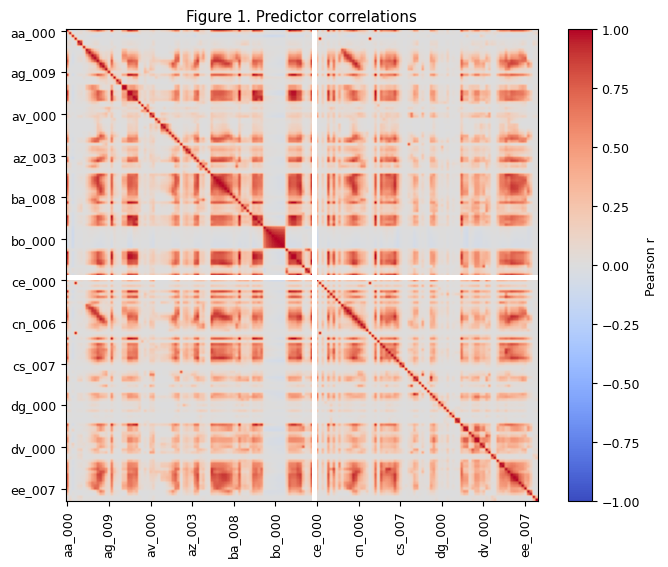

In [5]:
correlation = Xi_train.corr()
correlation.to_csv(results / "correlations.csv")
fig, ax = plt.subplots(figsize=(7, 5.7))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ticks = np.arange(0, 170, 15)
ax.set(
    xticks=ticks,
    yticks=ticks,
    xticklabels=X_train.columns[ticks],
    yticklabels=X_train.columns[ticks],
    title="Figure 1. Predictor correlations",
)
ax.tick_params(axis="x", rotation=90)
fig.colorbar(image, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

## 1(b)(iv). Highest-CV features
$\lfloor\sqrt{170}\rfloor=13$. Scatterplots show each selected feature
against the class, with slight horizontal jitter. To keep points visible,
they include all 1,000 positives and a fixed random sample of 2,000 negatives.
Boxplots use all training records, with outlier markers omitted. Both use
`log(1+x)` to display the long tails; CV and modeling use the original values.

**Scatterplots alone cannot establish statistical significance.** They reveal
possible differences but provide no adjusted effect estimates or uncertainty;
large CV can result from a tiny mean and rare extreme observations.

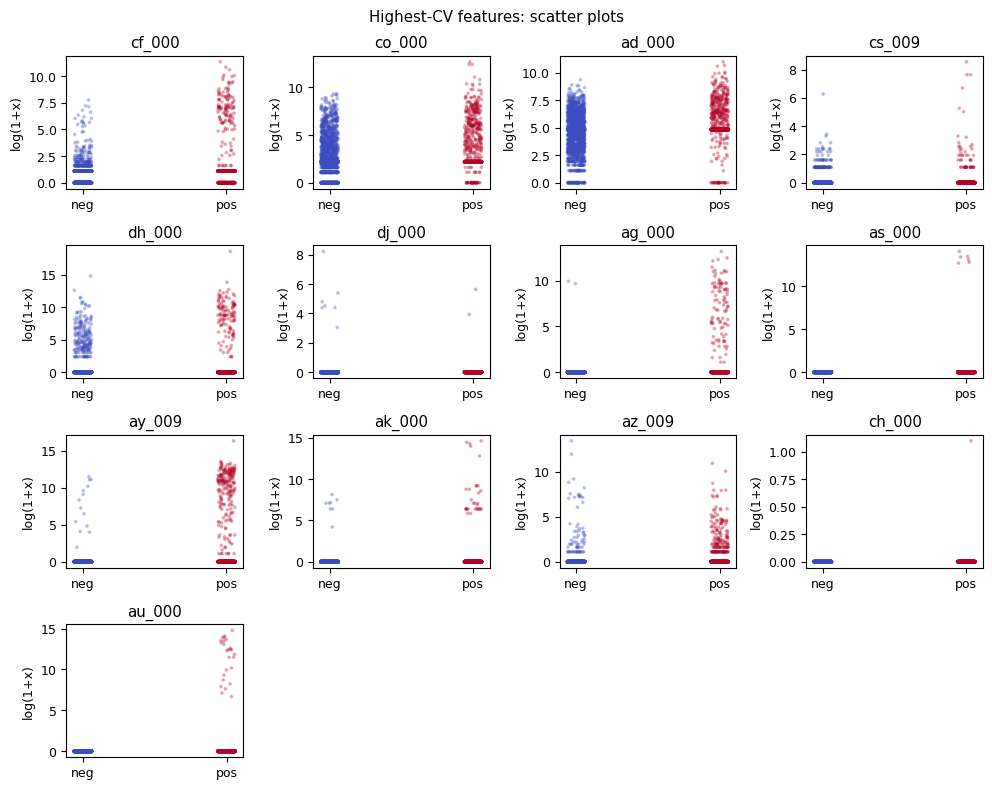

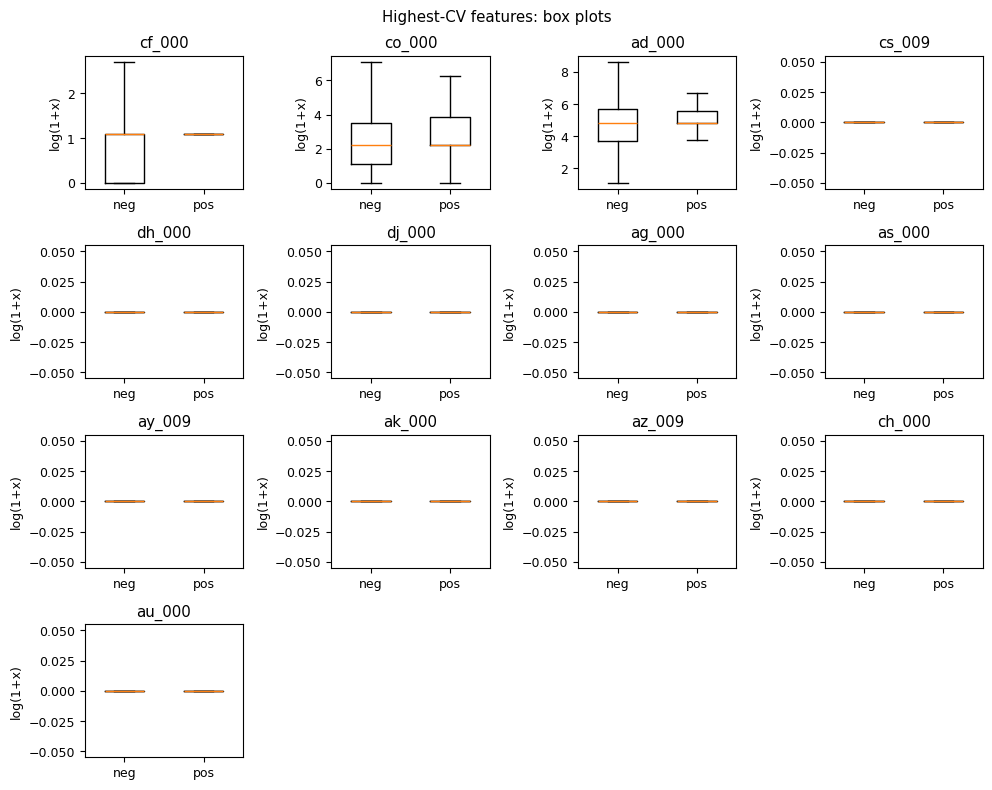

In [6]:
show_exploration(Xi_train, y_train, top_features)

## 1(b)(v). Class imbalance
The training set has **59,000 negatives and 1,000 positives (59:1)**; only
**1.67%** are positive. The test set has **15,625 negatives and 375 positives**
(**2.34%** positive). Always predicting negative gives 1.67% training error
and 2.34% test error, so recall and AUC must accompany total error.

## 1(c). Random forest without compensation
Use 300 bootstrap trees, Gini splits, `max_features="sqrt"`, unrestricted
depth, and seed 42. Class weights are absent. Confusion-matrix rows are actual
classes and columns are predicted classes; positive-class ROC uses probabilities.
OOB predictions average only trees that excluded each training observation.
The imputer is fitted once on training predictors, so this OOB estimate is
conditional on that preprocessing rather than a fully refitted pipeline.

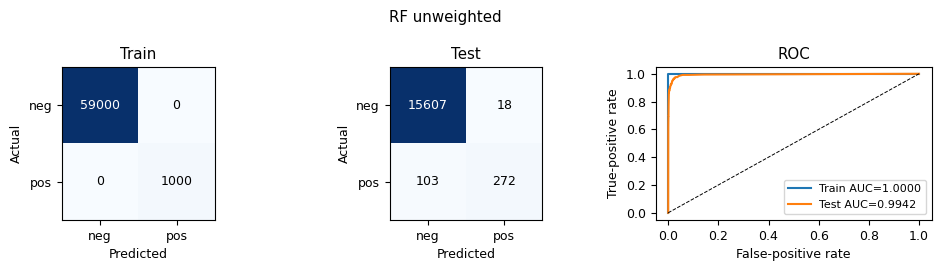

error     auc  recall  precision
model         split                                   
RF unweighted train 0.00000 1.00000 1.00000    1.00000
              test  0.00756 0.99423 0.72533    0.93793

,error,auc,recall
model,,,
RF unweighted,0.00577,0.98657,0.72600


In [7]:
metric_rows, oob_rows = [], []
predictions = {
    "train": pd.DataFrame({"actual": y_train}),
    "test": pd.DataFrame({"actual": y_test}),
}
fitted = {}
for name, weights in [("RF unweighted", None)]:
    model = RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        bootstrap=True,
        oob_score=True,
        class_weight=weights,
        n_jobs=4,
        random_state=42,
    )
    model.fit(Xi_train.to_numpy(), y_train)
    fitted[name] = model
    ptr = model.predict_proba(Xi_train.to_numpy())[:, 1]
    pte = model.predict_proba(Xi_test)[:, 1]
    report_model(
        name, y_train, y_test, ptr, pte, metric_rows, predictions
    )
    oob = model.oob_decision_function_[:, 1]
    assert np.all(model.oob_decision_function_.sum(axis=1) > 0)
    oob_rows.append({"model": name, **metrics(y_train, oob)})
    predictions["train"][name + " OOB"] = oob
    assert np.isclose(oob_rows[-1]["error"], 1 - model.oob_score_)
display(
    pd.DataFrame(metric_rows).set_index(["model", "split"])[
        ["error", "auc", "recall", "precision"]
    ]
)
display(
    pd.DataFrame(oob_rows).set_index("model")[
        ["error", "auc", "recall"]
    ]
)

## 1(d). Random forest with class compensation
Random forests can use inverse-frequency class weights, balanced bootstrap
samples, or over/undersampling. Here `class_weight="balanced_subsample"`
recomputes inverse-frequency weights within each bootstrap sample, giving
minority errors greater weight in split impurity. Tree settings and threshold
remain identical to 1(c); the original class counts are unchanged.

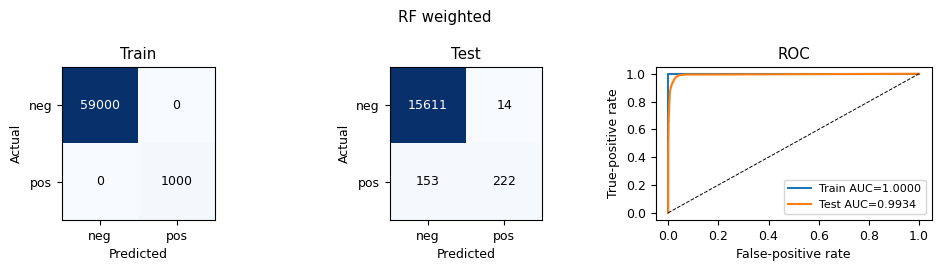

error     auc  recall  precision
model         split                                   
RF unweighted train 0.00000 1.00000 1.00000    1.00000
              test  0.00756 0.99423 0.72533    0.93793
RF weighted   train 0.00000 1.00000 1.00000    1.00000
              test  0.01044 0.99339 0.59200    0.94068

,error,auc,recall
model,,,
RF unweighted,0.00577,0.98657,0.72600
RF weighted,0.00763,0.98599,0.60300


In [8]:
name = "RF weighted"
model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight="balanced_subsample",
    n_jobs=4,
    random_state=42,
)
model.fit(Xi_train.to_numpy(), y_train)
fitted[name] = model
ptr = model.predict_proba(Xi_train.to_numpy())[:, 1]
pte = model.predict_proba(Xi_test)[:, 1]
report_model(name, y_train, y_test, ptr, pte, metric_rows, predictions)
oob = model.oob_decision_function_[:, 1]
assert np.all(model.oob_decision_function_.sum(axis=1) > 0)
oob_rows.append({"model": name, **metrics(y_train, oob)})
predictions["train"][name + " OOB"] = oob
assert np.isclose(oob_rows[-1]["error"], 1 - model.oob_score_)
display(
    pd.DataFrame(metric_rows).set_index(["model", "split"])[
        ["error", "auc", "recall", "precision"]
    ]
)
oob_table = pd.DataFrame(oob_rows).set_index("model")
display(oob_table[["error", "auc", "recall"]])
oob_table.to_csv(results / "random_forest_oob.csv")

## 1(e). L1-regularized XGBoost without compensation
Use binary logistic loss, 300 depth-four trees, learning rate 0.1, L2 penalty 1,
and five stratified folds (seed 42). Select $\alpha\in\{0,0.1,1,10\}$ by
mean validation misclassification error; ties select smaller alpha.
`scale_pos_weight=1` and no resampling leave class imbalance uncompensated.
The other parameters are fixed before evaluating the test set.

For XGBoost `gbtree`, `reg_alpha` penalizes **leaf weights**. Its axis-aligned
splits and constant leaf logits do **not** implement a separate L1 logistic
regression at each node as the handout describes. The implementation uses the
suggested XGBoost library, with that distinction explicit.

Fold-local median imputation and standardization precede fitting. Scaling
provides a common feature space for the SMOTE comparison; it does not create
an imbalance correction. The minimum CV error is a tuning estimate, not an
independent nested-CV estimate.

,alpha,cv_error,sd_error,cv_auc,cv_recall,se_error
0,0.00000,0.00557,0.00054,0.98854,0.75300,0.00024
1,0.10000,0.00537,0.00081,0.98866,0.75900,0.00036
2,1.00000,0.00552,0.00070,0.98912,0.75400,0.00031
3,10.00000,0.00625,0.00055,0.98981,0.71300,0.00025


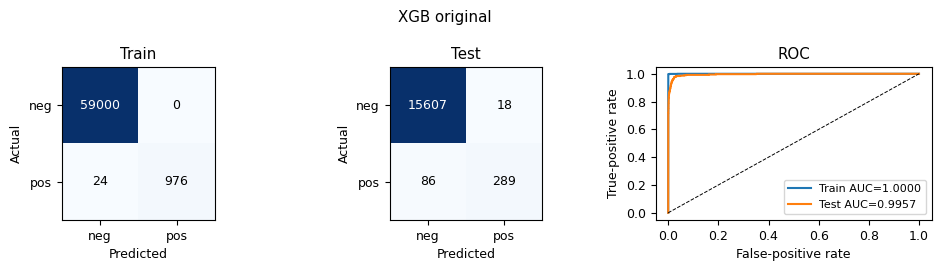

,error,auc,recall,precision
split,,,,
train,0.00040,0.99995,0.97600,1.00000
test,0.00650,0.99573,0.77067,0.94137


In [9]:
alpha_grid = [0.0, 0.1, 1.0, 10.0]
cv_tables, chosen_alpha, fold_sizes = {}, {}, {}
name = "XGB original"
folds, table, alpha, sizes = validate_boosting(
    X_train, y_train, alpha_grid, False, name
)
cv_tables[name], chosen_alpha[name] = table, alpha
fold_sizes[name] = sizes
folds.to_csv(results / "xgb_original_folds.csv", index=False)
table.to_csv(results / "xgb_original_cv.csv", index=False)
display(table)
scaler = StandardScaler().fit(Xi_train.to_numpy())
Z_train = scaler.transform(Xi_train.to_numpy()).astype(np.float32)
Z_test = scaler.transform(Xi_test).astype(np.float32)
model = xgb_model(alpha).fit(Z_train, y_train)
fitted[name] = model
report_model(
    name,
    y_train,
    y_test,
    model.predict_proba(Z_train)[:, 1],
    model.predict_proba(Z_test)[:, 1],
    metric_rows,
    predictions,
)
display(
    pd.DataFrame(metric_rows[-2:]).set_index("split")[
        ["error", "auc", "recall", "precision"]
    ]
)

## 1(f). SMOTE and XGBoost
SMOTE interpolates between a minority record and one of its five minority
neighbors in standardized feature space. Each training fold alone fits its
imputer and scaler, then applies SMOTE to balance that fold. Validation records
remain original and imbalanced. Resampling before forming folds would allow
related original/synthetic observations across training and validation.

The final fit uses **all 60,000 original training records**, producing
**59,000 observations per class (118,000 total)**. There is no majority-class
downsampling. Training metrics below use only the original 60,000 records;
test observations are never resampled. Alpha selection and tree settings
match 1(e).

,alpha,cv_error,sd_error,cv_auc,cv_recall,se_error
0,0.00000,0.00815,0.00067,0.98626,0.83700,0.00030
1,0.10000,0.00797,0.00055,0.98627,0.83600,0.00025
2,1.00000,0.00818,0.00096,0.98671,0.83800,0.00043
3,10.00000,0.00902,0.00109,0.98676,0.85400,0.00049


,fold,original,fitted,positives,negatives,valid,valid_pos
0,1,48000,94400,47200,47200,12000,200
1,2,48000,94400,47200,47200,12000,200
2,3,48000,94400,47200,47200,12000,200
3,4,48000,94400,47200,47200,12000,200
4,5,48000,94400,47200,47200,12000,200


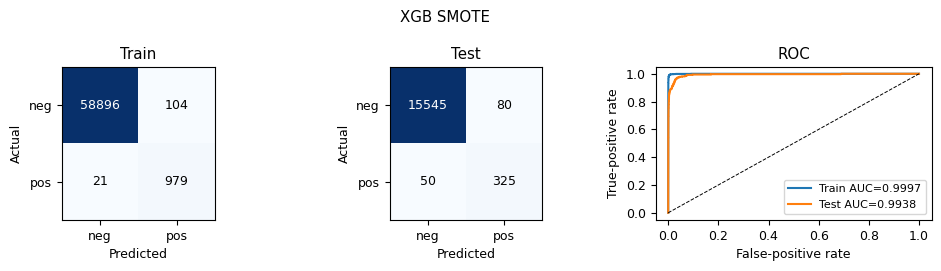

error     auc  recall  precision
model         split                                   
RF unweighted train 0.00000 1.00000 1.00000    1.00000
              test  0.00756 0.99423 0.72533    0.93793
RF weighted   train 0.00000 1.00000 1.00000    1.00000
              test  0.01044 0.99339 0.59200    0.94068
XGB original  train 0.00040 0.99995 0.97600    1.00000
              test  0.00650 0.99573 0.77067    0.94137
XGB SMOTE     train 0.00208 0.99971 0.97900    0.90397
              test  0.00813 0.99375 0.86667    0.80247

In [10]:
name = "XGB SMOTE"
folds, table, alpha, sizes = validate_boosting(
    X_train, y_train, alpha_grid, True, name
)
cv_tables[name], chosen_alpha[name] = table, alpha
fold_sizes[name] = sizes
folds.to_csv(results / "xgb_smote_folds.csv", index=False)
table.to_csv(results / "xgb_smote_cv.csv", index=False)
sizes.to_csv(results / "smote_fold_sizes.csv", index=False)
display(table)
display(
    sizes.rename(
        columns={
            "original_rows": "original",
            "fitted_rows": "fitted",
            "validation_rows": "valid",
            "validation_positives": "valid_pos",
        }
    )
)
Z_smote, y_smote = SMOTE(random_state=42, k_neighbors=5).fit_resample(
    Z_train, y_train
)
assert np.bincount(y_smote).tolist() == [59000, 59000]
model = xgb_model(alpha).fit(Z_smote, y_smote)
fitted[name] = model
report_model(
    name,
    y_train,
    y_test,
    model.predict_proba(Z_train)[:, 1],
    model.predict_proba(Z_test)[:, 1],
    metric_rows,
    predictions,
)
del Z_smote, y_smote
comparison = pd.DataFrame(metric_rows).set_index(["model", "split"])
display(comparison[["error", "auc", "recall", "precision"]])
comparison.to_csv(results / "model_metrics.csv")
for split, frame in predictions.items():
    frame.to_csv(results / f"{split}_predictions.csv", index=False)
for name, model in fitted.items():
    if name.startswith("XGB"):
        model.save_model(
            results / (name.lower().replace(" ", "_") + ".json")
        )
summary = {
    "chosen_alpha": chosen_alpha,
    "top_features": top_features,
    "train_rows": len(y_train),
    "test_rows": len(y_test),
    "smote_full_class_counts": [59000, 59000],
}
_ = (results / "selected_models.json").write_text(
    json.dumps(summary, indent=2) + "\n"
)

### Model comparison
Unweighted RF has **0.5767% OOB error versus 0.7563% test error**.
Weighted RF has **0.7633% OOB error versus 1.0438% test error**.
OOB is optimistic by 0.1796 and 0.2804 percentage points, respectively.
Both forests fit the training labels perfectly, so training error alone is
misleading. Weighting lowers positive recall from **72.53% to 59.20%**;
compensation does not guarantee better performance at a fixed threshold.

Both boosted models select **alpha = 0.1**. Original XGBoost has **0.5367%
CV error versus 0.6500% test error**; SMOTE XGBoost has **0.7967% CV error
versus 0.8125% test error**. These are selected-model tuning scores, with
natural imbalanced validation/test distributions.

SMOTE increases test recall from **77.07% to 86.67%**, reducing false
negatives from **86 to 50**, but false positives rise from **18 to 80**.
Precision falls from **94.14% to 80.25%** and AUC from **0.99573 to 0.99375**.
Original XGBoost has the lowest observed total test error; SMOTE favors finding
more APS failures at the cost of extra inspections. The comparison is for the
fixed 0.5 threshold and does not use test results to retune the models.

,alpha,CV error,test error
model,,,
XGB original,0.10000,0.00537,0.00650
XGB SMOTE,0.10000,0.00797,0.00813


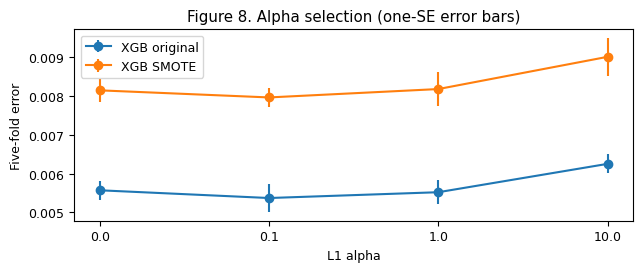

In [11]:
cv_comparison = pd.DataFrame(
    [
        {
            "model": name,
            "alpha": chosen_alpha[name],
            "CV error": table.loc[
                table.alpha.eq(chosen_alpha[name]), "cv_error"
            ].iloc[0],
            "test error": comparison.loc[(name, "test"), "error"],
        }
        for name, table in cv_tables.items()
    ]
).set_index("model")
display(cv_comparison)
cv_comparison.to_csv(results / "cv_test_comparison.csv")
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for name, table in cv_tables.items():
    ax.errorbar(
        np.arange(len(alpha_grid)),
        table.cv_error,
        yerr=table.se_error,
        marker="o",
        label=name,
    )
ax.set(
    xticks=np.arange(len(alpha_grid)),
    xticklabels=alpha_grid,
    xlabel="L1 alpha",
    ylabel="Five-fold error",
    title="Figure 8. Alpha selection (one-SE error bars)",
)
ax.legend()
fig.tight_layout()
plt.show()

### Test-median sensitivity (handout footnote)
For this additional comparison, fit medians separately on the unlabeled test
batch, then reuse the already fitted models and training scalers. No model
is retuned. This reports the footnote's procedure alongside the main inductive
analysis; a deployment receiving only one record cannot estimate these batch
medians in the same way.

In [12]:
test_batch_imputer = SimpleImputer(strategy="median")
X_test_batch = test_batch_imputer.fit_transform(X_test)
assert X_test_batch.shape == Xi_test.shape
sensitivity = []
for name, model in fitted.items():
    values = (
        scaler.transform(X_test_batch).astype(np.float32)
        if name.startswith("XGB")
        else X_test_batch
    )
    probability = model.predict_proba(values)[:, 1]
    sensitivity.append(
        {
            "model": name,
            "main_test_error": comparison.loc[(name, "test"), "error"],
            "test_batch_median_error": metrics(y_test, probability)[
                "error"
            ],
            "test_batch_median_auc": metrics(y_test, probability)[
                "auc"
            ],
        }
    )
sensitivity = pd.DataFrame(sensitivity).set_index("model")
display(sensitivity)
sensitivity.to_csv(results / "test_median_sensitivity.csv")

,main_test_error,test_batch_median_error,test_batch_median_auc
model,,,
RF unweighted,0.00756,0.00762,0.99423
RF weighted,0.01044,0.01050,0.99340
XGB original,0.00650,0.00644,0.99575
XGB SMOTE,0.00813,0.01275,0.99253


## 2. ISLR 6.6.3: Increasing the LASSO constraint
Minimize RSS subject to $\sum_j|\beta_j|\le s$. Increasing $s$ enlarges the
feasible set, moving from an intercept-only fit toward least squares.

| Part | Quantity | Choice | Behavior and reason |
|---|---|---|---|
| (a) | Training RSS | iv | Nonincreasing: every previously feasible fit remains feasible; it plateaus once the constraint is inactive. |
| (b) | Test RSS | ii | Typically decreases then increases: reduced underfitting is eventually offset by estimation variance. |
| (c) | Variance | iii | Generally increases as the coefficients become less constrained. |
| (d) | Squared bias | iv | Generally decreases as the model becomes more flexible. |
| (e) | Irreducible error | v | Constant: changing the estimator does not change the noise distribution. |

The bias/variance and test-error curves describe the usual expected pattern,
not guaranteed monotonic behavior for every realized dataset.

## 3. ISLR 6.6.5: Identical predictors in ridge and LASSO
Let $x_i=x_{i1}=x_{i2}$, $b=\beta_1+\beta_2$, $S=\sum_i x_i^2>0$,
and $T=\sum_i x_i y_i$. Centering gives intercept zero; assume $\lambda>0$.

**(a)** Ridge minimizes
$$\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2).$$
**(b)** For fixed $b$, the unique minimum penalty occurs at
$\beta_1=\beta_2=b/2$, since
$\beta_1^2+\beta_2^2=b^2/2+(\beta_1-\beta_2)^2/2$.
Thus $\hat b=T/(S+\lambda/2)$ and both coefficients equal $\hat b/2$.

**(c)** LASSO minimizes
$$\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|).$$
**(d)** By the triangle inequality, the smallest penalty for fixed $b$ is
$\lambda|b|$, attained by any same-sign split of $b$. The optimal sum is
$$\hat b=\frac{\operatorname{sign}(T)(|T|-\lambda/2)_+}{S}.$$
If $\hat b>0$, all $(t,\hat b-t)$ with $0\le t\le\hat b$ minimize the
objective; if $\hat b<0$, use $\hat b\le t\le0$. Predictions are identical
although the individual coefficients differ. If shrinkage gives $\hat b=0$,
the positive-penalty solution is uniquely $(0,0)$; the claimed nonuniqueness
requires a nonzero fitted sum.

## 4. ISLR 8.4.5: Majority vote versus average probability
The ten red-class probabilities are
$0.1,0.15,0.2,0.2,0.55,0.6,0.6,0.65,0.7,0.75$.

**Majority vote: Red**, because six of ten trees assign probability above 0.5.
**Average probability: Green**, because the average is $4.5/10=0.45<0.5$.
Voting weights every decision equally; averaging also uses confidence, and the
four low probabilities outweigh the six modest red preferences.

## 5. ISLR 9.7.3: Maximal margin classifier
**(a)** The labeled observations appear in the left panel below.

**(b–c)** The optimal boundary is $X_2=X_1-0.5$. With Red encoded $+1$,
$f(X)=0.5-X_1+X_2$: predict Red when $f(X)>0$ and Blue otherwise.
Thus $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$; positive rescaling is equivalent.

**(d)** The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$.
The distance from the separating line to either boundary is
$0.5/\sqrt{2}=1/(2\sqrt{2})\approx0.3536$; total margin width is $1/\sqrt2$.

**(e)** Observations **2, 3, 5, and 6** lie on the margin boundaries.
The closest red and blue convex-hull faces lie on those parallel lines,
so their midpoint achieves the largest possible separating margin.

**(f)** Observation 7, $(4,1)$, has signed score $-2.5$, well outside the blue
margin. A sufficiently small movement leaves the supporting faces unchanged,
so it does not affect the maximal margin boundary.

**(g)** $X_2=X_1-0.25$ also separates every observation, but its minimum
point-to-line distance is only $0.25/\sqrt2$, so it is not optimal.

**(h)** Add a Red observation at $(3,1.5)$, strictly inside the Blue triangle formed by
observations 5, 6, and 7. No hyperplane can separate a point inside the convex
hull of the opposite class. The right panel shows this added observation.

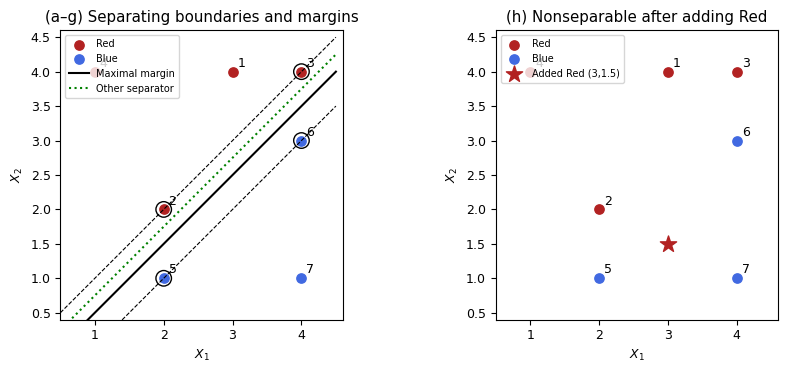

boundary_intercept    1.00000
beta1                -2.00000
beta2                 2.00000
one_side_margin       0.35355
dtype: float64

In [13]:
toy = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
toy_y = np.array([1, 1, 1, 1, -1, -1, -1])
svm = SVC(kernel="linear", C=1e6, tol=1e-9).fit(toy, toy_y)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
x = np.linspace(0.5, 4.5, 100)
for ax in axes:
    ax.scatter(*toy[:4].T, color="firebrick", label="Red", s=45)
    ax.scatter(*toy[4:].T, color="royalblue", label="Blue", s=45)
    for i, (a, b) in enumerate(toy, 1):
        ax.annotate(str(i), (a + 0.07, b + 0.07))
    ax.set(
        xlim=(0.5, 4.6),
        ylim=(0.4, 4.6),
        xlabel="$X_1$",
        ylabel="$X_2$",
        aspect="equal",
    )
axes[0].plot(x, x - 0.5, "k-", label="Maximal margin")
axes[0].plot(x, x, "k--", linewidth=0.8)
axes[0].plot(x, x - 1, "k--", linewidth=0.8)
axes[0].plot(
    x, x - 0.25, color="green", linestyle=":", label="Other separator"
)
axes[0].scatter(
    *toy[[1, 2, 4, 5]].T, s=125, facecolors="none", edgecolors="black"
)
axes[0].set_title("(a–g) Separating boundaries and margins")
axes[0].legend(fontsize=7, loc="upper left")
axes[1].scatter(
    3,
    1.5,
    color="firebrick",
    marker="*",
    s=150,
    label="Added Red (3,1.5)",
)
axes[1].set_title("(h) Nonseparable after adding Red")
axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()
display(
    pd.Series(
        {
            "boundary_intercept": svm.intercept_[0],
            "beta1": svm.coef_[0, 0],
            "beta2": svm.coef_[0, 1],
            "one_side_margin": 1 / np.linalg.norm(svm.coef_),
        }
    )
)

## References
1. [APS Failure at Scania Trucks](https://doi.org/10.24432/C51S51), UCI.
2. [Scikit-learn imputation](https://scikit-learn.org/1.5/modules/impute.html)
   and [random forests](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
3. [XGBoost parameters](https://xgboost.readthedocs.io/en/release_2.1.0/parameter.html).
4. [SMOTE](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html)
   and [resampling pitfalls](https://imbalanced-learn.org/stable/common_pitfalls.html).
5. James, Witten, Hastie, and Tibshirani (2021). *An Introduction to Statistical
   Learning*, second edition: exercises 6.6.3, 6.6.5, 8.4.5, and 9.7.3.
   [Textbook site](https://www.statlearning.com/).

## AI disclosure
ChatGPT was used to understand requirements and concepts, assist with code,
debug errors, and check results.